In [8]:
from scripts.general_nn import generalNN
from scripts import plots
import importlib


In [12]:
from dataclasses import replace

from scripts.general_nn import generalNN
from scripts.settings import Settings
from scripts import plots, plots1


# Use a small training budget for this first experiment.
settings = Settings(
    warmup_updates=100,
    continuation_updates=100,
    number_of_replicates=1,

    # Check validation performance every 25 training updates.
    validation_interval=25,

    # Set the sizes of the calibration, validation, and test datasets.
    normalization_size=2048,
    validation_size=2048,
    test_size=8192,

    # Used only if we choose to train from a fixed dataset.
    static_training_size=8192,
)

# True: generate fresh training batches.
# False: sample batches from one fixed training dataset.
dynamic_data = True

In [3]:
# Create a new paper-style model that can trade stock and the variance claim.
paper = generalNN(
    method="paper",
    settings=settings,
    dynamic_data=dynamic_data,
)

# Copy the settings and disable trading in the variance claim.
control_settings = replace(settings, trade_variance=False)

# Create a new paper-style model restricted to stock trading.
control = generalNN(
    method="paper",
    settings=control_settings,
    dynamic_data=dynamic_data,
)

# Create a new model using our smaller network design.
ours = generalNN(
    method="ours",
    settings=settings,
    dynamic_data=dynamic_data,
)

In [4]:
method="paper"

In [5]:
# Train and evaluate each newly created model.
for model in (paper, control, ours):

    print(f"\nTraining: {model.name}")

    # Prepare the training data and fit the hedging policies.
    model.train(verbose=True)

    # Measure the trained policies on separate test paths.
    model.evaluate()


Training: Paper style: stock + variance
paper_full_0_warmup: update 0, validation risk 6.35469
paper_full_0_warmup: update 100, validation risk 2.68073
paper_full_0_CVaR: update 0, validation risk 2.68123
paper_full_0_CVaR: update 100, validation risk 2.55219
paper_full_0_Entropic: update 0, validation risk 9.65577
paper_full_0_Entropic: update 100, validation risk 7.54554

Training: Paper style: stock only
paper_stock_0_warmup: update 0, validation risk 5.22710
paper_stock_0_warmup: update 100, validation risk 2.89610
paper_stock_0_CVaR: update 0, validation risk 2.89366
paper_stock_0_CVaR: update 100, validation risk 2.82940
paper_stock_0_Entropic: update 0, validation risk 15.41962
paper_stock_0_Entropic: update 100, validation risk 13.88429

Training: Our network: stock only
ours_0_warmup: update 0, validation risk 4.15072
ours_0_warmup: update 100, validation risk 2.79663
ours_0_CVaR: update 0, validation risk 2.79663
ours_0_CVaR: update 100, validation risk 2.76602
ours_0_Entrop

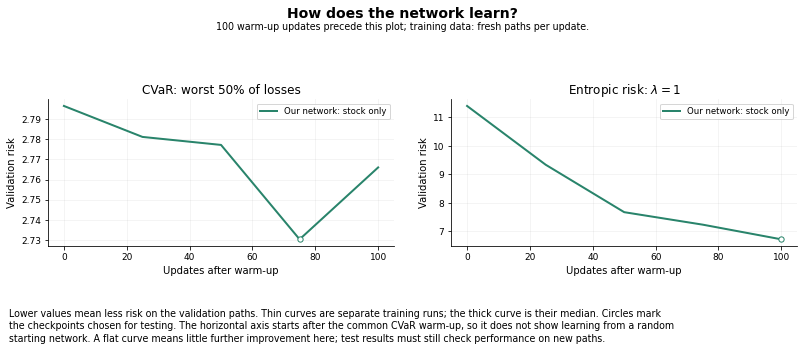

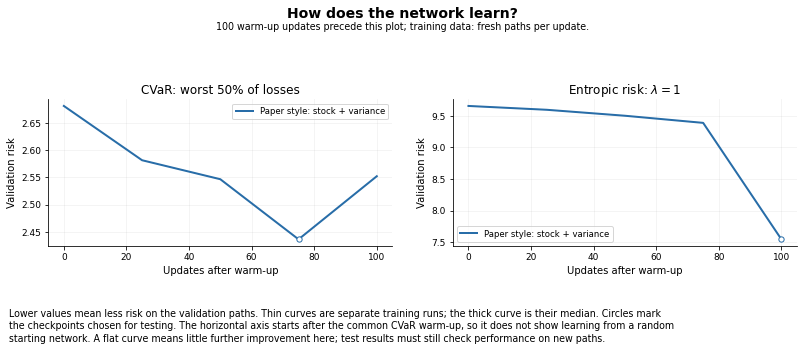

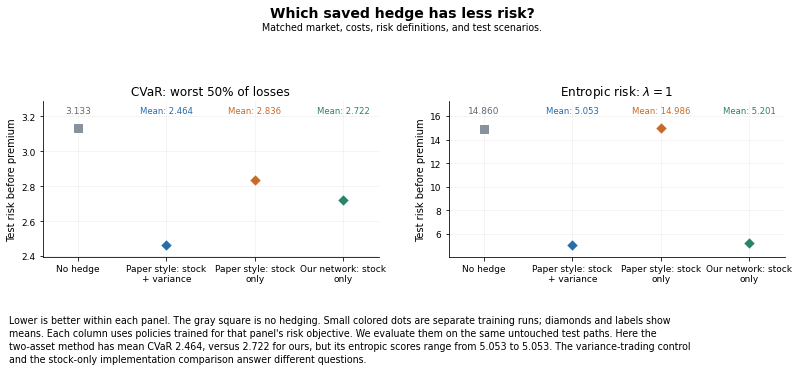

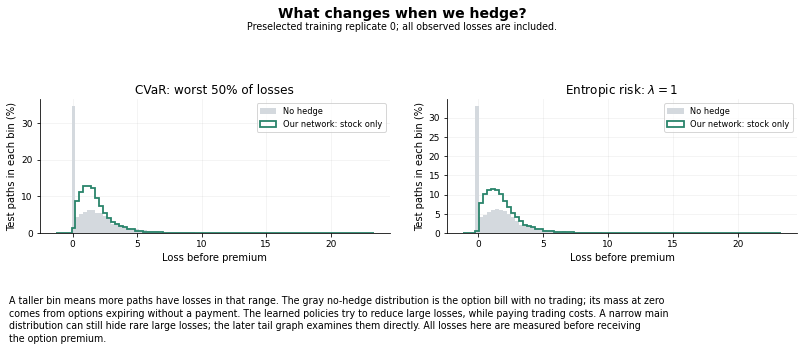

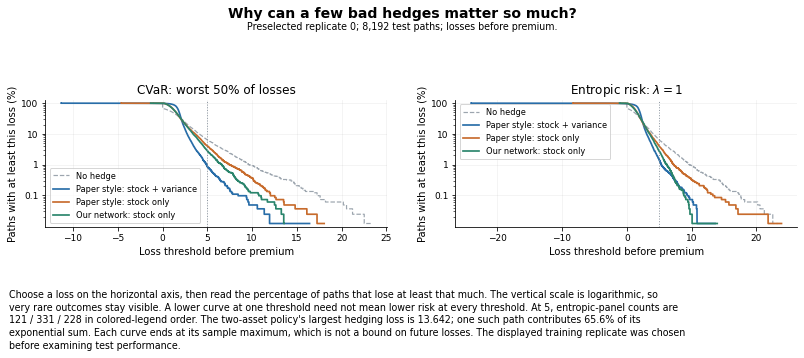

In [6]:
# Show how our model learned.
plots.plot_learning(ours)

# Show how the paper-style model learned.
plots.plot_learning(paper)

# Compare the test risk of all three models.
plots.plot_risk([paper, control, ours])

# Examine the loss distribution for our model.
plots.plot_losses(ours)

# Compare the frequencies of large losses.
plots.plot_loss_tails([paper, control, ours])

In [19]:
from dataclasses import replace

from scripts.general_nn import generalNN
from scripts import plots

# Keep our settings, but use the same instruments as the full reference.
settings_with_variance = replace(
    ours.settings,
    instruments=paper.settings.instruments,
    trade_variance=True,
)

ours_variance = generalNN(
    method="ours",
    settings=settings_with_variance,
    dynamic_data=ours.dynamic_data,
    name="Our network: stock + variance",
)

In [21]:
print(ours_variance.network.networks[0])

print("Inputs:", ours_variance.settings.input_size)
print("Outputs:", ours_variance.settings.output_size)
print("Parameters:", ours_variance.parameter_count)

Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): Tanh()
  (2): Linear(in_features=16, out_features=16, bias=True)
  (3): Tanh()
  (4): Linear(in_features=16, out_features=2, bias=True)
)
Inputs: 4
Outputs: 2
Parameters: 11580


In [ ]:
ours_variance.train(
    objectives=("CVaR", "Entropic"),
    verbose=True,
)

ours_variance.evaluate()

ours_0_warmup: update 0, validation risk 4.29552


In [ ]:
experiments = [paper, control, ours, ours_variance]

plots.plot_learning(experiments)
plots.plot_risk(experiments)
plots.plot_loss_tails(experiments)

In [ ]:
plots.plot_risk([ours, ours_variance])

plots.plot_loss_tails(
    [ours, ours_variance],
    objective="Entropic",
)

In [20]:
importlib.reload(plots)

<module 'scripts.plots' from '/mnt/c/Users/USER/Documents/GitHub/Deep-Hedging-Implementation/scripts/plots.py'>

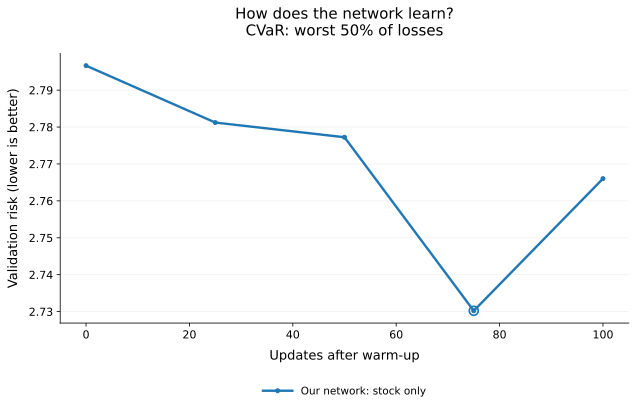

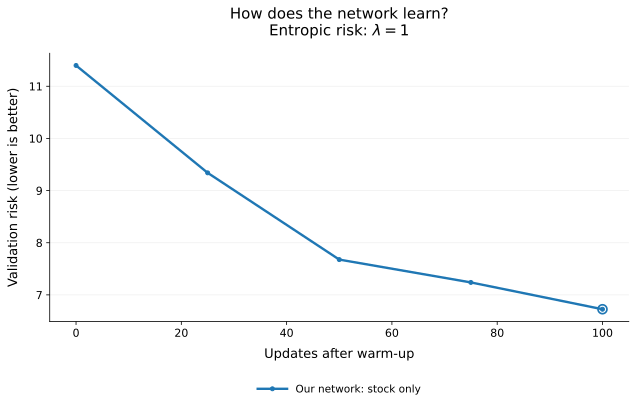

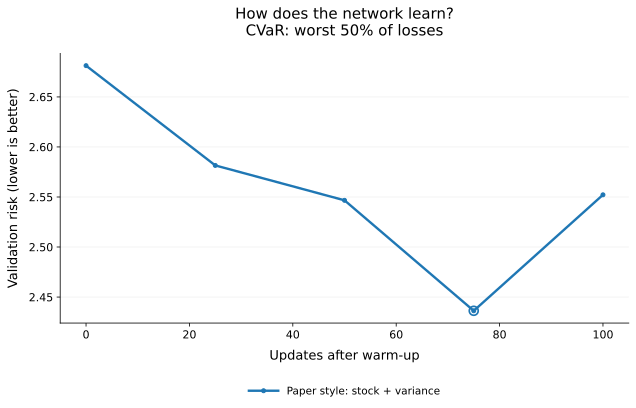

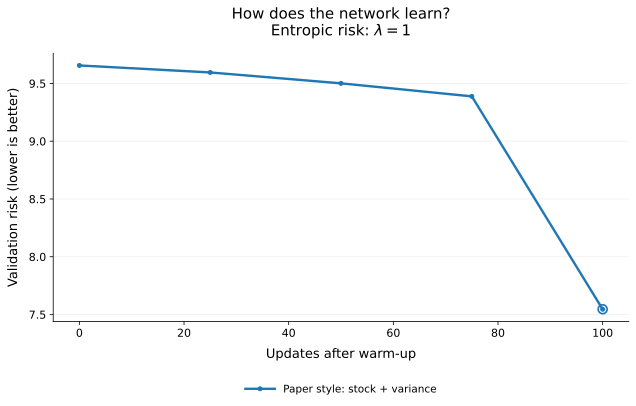

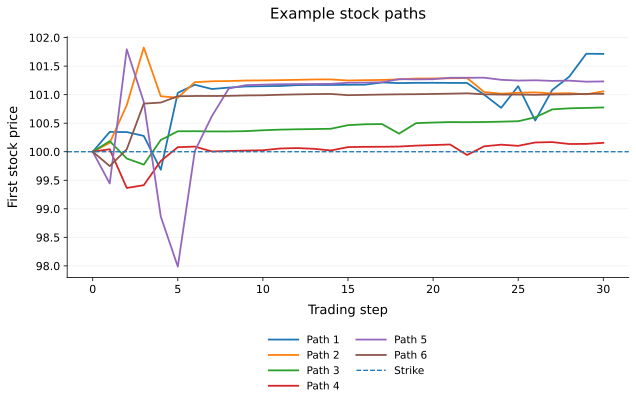

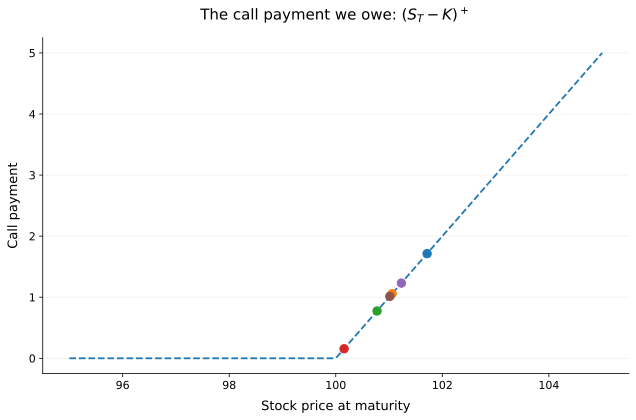

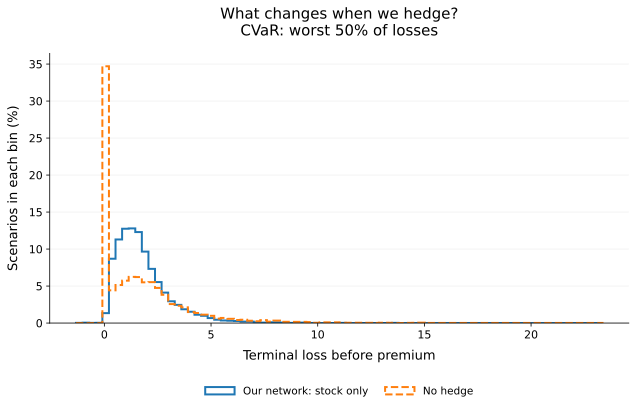

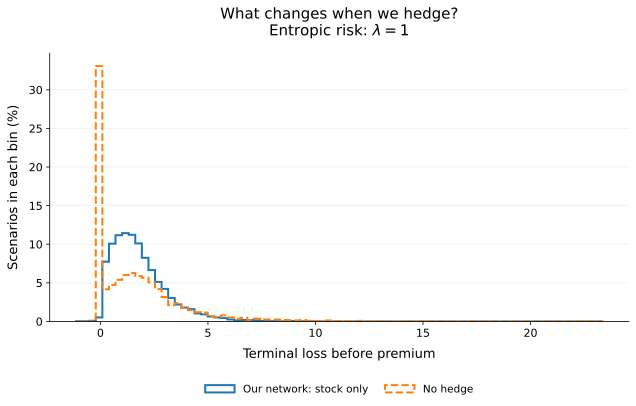

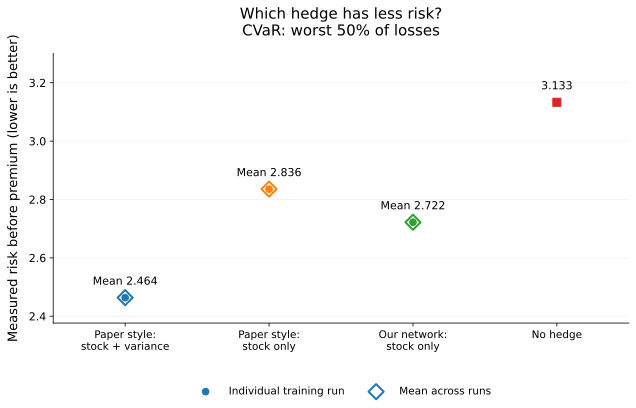

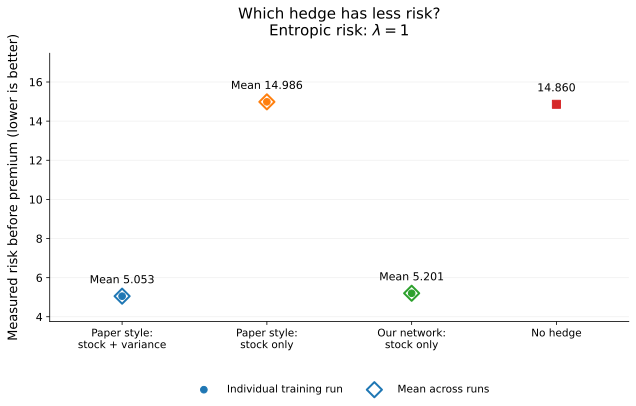

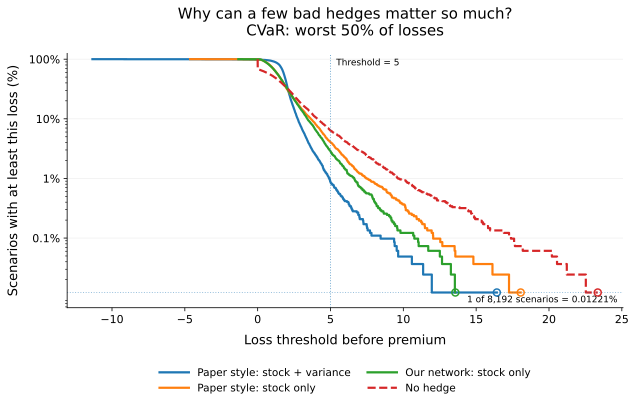

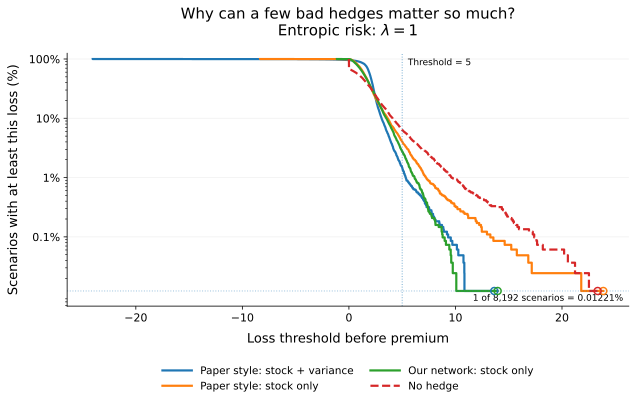

In [13]:
plots1.plot_learning(ours)
plots1.plot_learning(paper)

plots1.plot_paths(ours)
plots1.plot_losses(ours)

plots1.plot_risk([paper, control, ours])
plots1.plot_loss_tails([paper, control, ours])

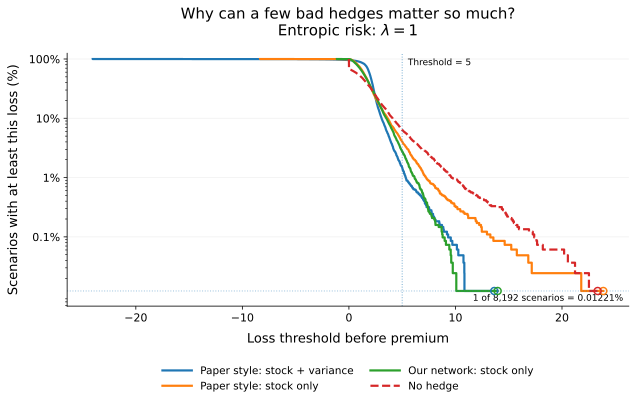

In [15]:
plots1.plot_loss_tails(
    [paper, control, ours],
    objective="Entropic",
)

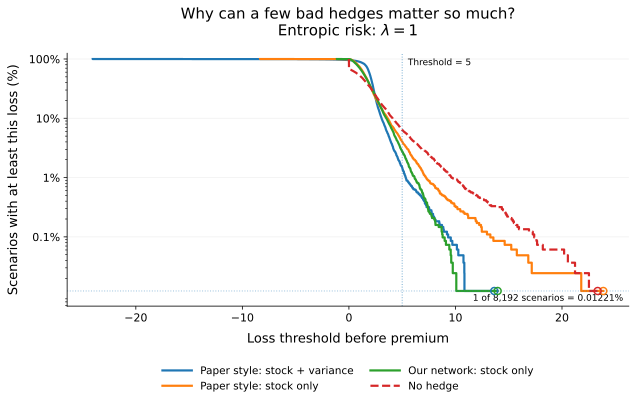

**How to read this graph.** Choose a loss threshold on the horizontal axis, then read the percentage of evaluation scenarios with loss at least that large. A lower curve at that threshold means fewer exceedances. The vertical axis is logarithmic: adjacent decade ticks represent a factor of ten. Each open endpoint is the largest loss in that sample, not a bound on future loss. The dotted horizontal line marks one scenario. A horizontal tail is an interval with no intervening observed losses, not missing data. All sample extremes are shown, without smoothing or interpolation of probabilities. These are scenario frequencies, not the exponential weights used by entropic risk. The figure uses the configured display replicate (or the requested replicate), not a pooled sample of training runs. For the displayed runs, Paper style: stock + variance: maximum loss 13.642; one maximum-loss scenario has 65.6% of the exponential weight; Paper style: stock only: maximum loss 23.875; one maximum-loss scenario has 88.6% of the exponential weight; Our network: stock only: maximum loss 13.958; one maximum-loss scenario has 77.5% of the exponential weight.

In [17]:
plots1.plot_loss_tails(
    [paper, control, ours],
    objective="Entropic",
    explain=True,
    save_dir="figures",
)